# 06_recommendation_inference.ipynb — Model Recommendation Evidence, Inference Pipeline & Limitations

**Module:** NB6057CEM Artificial Neural Networks — CW1 Practical  
**Task:** Task T5a, T5b & T5c — Benchmarking, Evidence, Recommendation, Inference CLI & Limitations (8 marks); plus a T6b config-to-result trace  
**Dataset:** MotionSense (A_DeviceMotion_data) — Malekzadeh et al. (2018/2019)  

---

### Coursework Brief Requirements (Task T5)
Task T5 evaluates the translation of empirical machine learning models into real-world deployable Human Activity Recognition (HAR) systems:
1. **Model Complexity & Latency Benchmarking (Task T5a)**:
   - Measure trainable parameter counts for neural networks and total tree nodes for Random Forest.
   - Measure model serialization file sizes on disk (in MB).
   - Profile CPU inference latency on **validation windows strictly** under two conditions:
     - **Model-Only**: preprocessed feature vectors or preprocessed raw sequence windows.
     - **End-to-End**: raw sensor stream windows ($128 \times 12$) through feature extraction/scaling to final prediction.
   - Profile batch size 1 (real-time single-window streaming) and batch size 256 (batched offline throughput).
   - Fix PyTorch CPU thread count and report mean, standard deviation, and median latency over 100 runs following 10 warm-up runs.
2. **Recommendation Evidence Matrix (Task T5a)**:
   - Combine validation and test macro-F1, worst-subject test F1, noise robustness at $\sigma \in \{0.25, 0.50\}$, parameter counts, file sizes, and CPU latencies into a structured evidence table (`outputs/metrics/recommendation_evidence.csv`).
   - Plot Figure 19: Latency vs Test Macro-F1 trade-off (`outputs/figures/fig19_tradeoff.png`).
   - Give a recommendation that follows from this evidence, including when a simpler model is preferable (section 3).
3. **Inference CLI Pipeline (Task T5b)**:
   - Provide a modular CLI engine (`src/predict.py`) operating on arbitrary 50 Hz MotionSense sensor recordings.
   - Implement strict input integrity validation with clear error messages and non-zero exit codes (no Python tracebacks).
   - Implement out-of-scope domain shift warnings (channel range deviations $>10\%$, gravity norm $|\text{norm} - 1| > 0.05\text{ g}$, low confidence $< 0.50$).
   - Support both human-readable ASCII tables and structured `--json` output.
4. **Limitations & Future Directions (Task T5c)**:
   - Outline critical limitations: dataset bias, generalisation boundaries, privacy & misuse risks, and next proposed experiments.


In [1]:
import json
import subprocess
import sys
from pathlib import Path

import IPython.display as ipd
import numpy as np
import pandas as pd

# Confirm working directory and paths
print(f"Python executable: {sys.executable}")
print(f"Working directory: {Path.cwd()}")


Python executable: C:\Users\Isuru\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
Working directory: C:\Users\Isuru\Desktop\ANN


## 1. Hardware Environment & Benchmark Methodology (Task T5a)

To ensure scientific reproducibility, latency profiling was executed under standardized hardware conditions:
- **Processor**: Intel 11th Gen Core i5-11400H @ 2.70 GHz (6 physical cores, 12 threads).
- **Execution Mode**: CPU-only inference on a laptop. A phone would be slower, so these timings compare the models with each other rather than predicting phone latency.
- **PyTorch Threading**: Pinned to 6 threads (`torch.set_num_threads(6)`).
- **Profiling Input**: **Validation windows strictly** (`outputs/cache/X_val_raw.npy`, `X_val_feat_scaled.npy`, `X_val_raw_scaled.npy`). In strict adherence to Project Rules, the test set was **never loaded or unblinded** for timing.
- **Timing Protocol**: High-resolution `time.perf_counter()` over 100 timed runs following 10 warm-up runs to eliminate JIT compilation, caching, and CPU frequency governor artifacts.


In [2]:
# Load benchmark metrics from outputs/metrics/benchmark.json
benchmark_path = Path("outputs/metrics/benchmark.json")
with open(benchmark_path, "r", encoding="utf-8") as f:
    benchmark_data = json.load(f)

env_info = benchmark_data["environment"]
print("=" * 75)
print("BENCHMARK EXECUTION ENVIRONMENT:")
print(f"  CPU Model:       {env_info['cpu_name']}")
print(f"  Operating System:{env_info['os']}")
print(f"  Python Version:  {env_info['python_version']}")
print(f"  PyTorch Version: {env_info['torch_version']}")
print(f"  scikit-learn:    {env_info['sklearn_version']}")
print(f"  CPU Threads:     {env_info['torch_num_threads']}")
print("=" * 75)

# Build comprehensive latency profiling summary table
bench_rows = []
for model_key, m_info in benchmark_data["models"].items():
    lat = m_info["latency"]
    
    # Model-only
    mo_b1_mean = lat["model_only"]["batch_1"]["mean_ms"]
    mo_b1_std = lat["model_only"]["batch_1"]["std_ms"]
    mo_b1_med = lat["model_only"]["batch_1"]["median_ms"]
    mo_b256_per_win = lat["model_only"]["batch_256"]["per_window_mean_ms"]
    
    # End-to-end
    e2e_b1_mean = lat["end_to_end"]["batch_1"]["mean_ms"]
    e2e_b1_std = lat["end_to_end"]["batch_1"]["std_ms"]
    e2e_b1_med = lat["end_to_end"]["batch_1"]["median_ms"]
    e2e_b256_per_win = lat["end_to_end"]["batch_256"]["per_window_mean_ms"]
    
    size_str = f"{m_info['size_metric_value']:,} {m_info['size_metric_name']}"
    file_mb = f"{m_info['checkpoint_file_size_mb']:.2f} MB"
    
    bench_rows.append({
        "Model": m_info["display_name"],
        "Complexity": size_str,
        "File Size": file_mb,
        "Model-Only B=1 [ms]": f"{mo_b1_mean:.3f} ± {mo_b1_std:.3f} (med: {mo_b1_med:.3f})",
        "Model-Only B=256 [ms/win]": f"{mo_b256_per_win:.4f}",
        "End-to-End B=1 [ms]": f"{e2e_b1_mean:.2f} ± {e2e_b1_std:.2f} (med: {e2e_b1_med:.2f})",
        "End-to-End B=256 [ms/win]": f"{e2e_b256_per_win:.4f}",
    })

df_bench = pd.DataFrame(bench_rows)
ipd.display(df_bench)


BENCHMARK EXECUTION ENVIRONMENT:
  CPU Model:       11th Gen Intel(R) Core(TM) i5-11400H @ 2.70GHz
  Operating System:Windows 10 (10.0.26200, AMD64)
  Python Version:  3.11.9
  PyTorch Version: 2.15.0+cpu
  scikit-learn:    1.7.2
  CPU Threads:     6


,Model,Complexity,File Size,Model-Only B=1 [ms],Model-Only B=256 [ms/win],End-to-End B=1 [ms],End-to-End B=256 [ms/win]
0,Random Forest,"208,268 tree nodes",22.37 MB,7.182 ± 0.347 (med: 7.095),0.1467,7.56 ± 0.43 (med: 7.47),0.2016
1,PyTorch MLP,"19,910 trainable parameters",0.08 MB,0.099 ± 0.011 (med: 0.095),0.0008,0.48 ± 0.06 (med: 0.46),0.0610
2,PyTorch 1D-CNN,"128,454 trainable parameters",0.50 MB,0.375 ± 0.065 (med: 0.352),0.0797,0.44 ± 0.06 (med: 0.43),0.0815


## 2. Multi-Criteria Recommendation Evidence Matrix (Task T5a)

The table below synthesises the complete empirical evidence across accuracy, generalisation gap, demographic fairness, sensor noise robustness, model size, and inference latency.

The recommendation based on this table is given in section 3. All numbers originate strictly from saved artifacts (`results_summary.json`, `noise_robustness.json`, `subgroup.json`, `benchmark.json`).


In [3]:
evidence_csv_path = Path("outputs/metrics/recommendation_evidence.csv")
df_evidence = pd.read_csv(evidence_csv_path)

# Display formatted table
styled_table = df_evidence.style.set_table_styles([
    {"selector": "th", "props": [("background-color", "#2b5c8f"), ("color", "white"), ("font-weight", "bold"), ("text-align", "center")]},
    {"selector": "td", "props": [("text-align", "center"), ("padding", "6px 12px")]},
    {"selector": "caption", "props": [("caption-side", "top"), ("font-size", "14px"), ("font-weight", "bold"), ("padding-bottom", "8px")]}
]).set_caption("Table 1: Multi-Criteria HAR Model Recommendation Evidence Matrix (Tasks T5a)")

ipd.display(styled_table)


,model,display_name,representative_seed,test_macro_f1,val_macro_f1,worst_subject_test_f1,f1_noise_sigma_0_25,f1_noise_sigma_0_50,size_metric,file_size_mb,e2e_latency_batch_1_ms,e2e_latency_batch_256_per_window_ms,threading_setting
0,baseline_rf,Random Forest,1,0.8860 ± 0.0016,0.9302 ± 0.0057,0.8244 (Sub 18),0.8038 ± 0.0039,0.2326 ± 0.0031,"208,268 tree nodes",22.370000,7.56 ± 0.43,0.201600,n_jobs=1 (b1) / n_jobs=-1 (b256)
1,pytorch_mlp,PyTorch MLP,0,0.8849 ± 0.0078,0.9574 ± 0.0053,0.8034 (Sub 1),0.7467 ± 0.0154,0.2166 ± 0.0081,"19,910 params",0.080000,0.48 ± 0.06,0.061000,torch_num_threads=6
2,pytorch_cnn_1d,PyTorch 1D-CNN,2,0.8615 ± 0.0293,0.9525 ± 0.0128,0.8061 (Sub 21),0.8518 ± 0.0170,0.6064 ± 0.0109,"128,454 params",0.500000,0.44 ± 0.06,0.081500,torch_num_threads=6


## 3. Generalisation vs Latency Trade-Off Analysis (Figure 19)

Figure 19 illustrates the multi-objective Pareto trade-off between **held-out test macro-F1** (y-axis, with $\pm 1\sigma$ inter-seed error bars) and **end-to-end CPU inference latency** for batch size 1 (x-axis, log scale). Marker bubble size is proportional to checkpoint serialization file size on disk (MB).

### Key Empirical Findings:
1. **Random Forest Baseline**:
   - Ties with the MLP for the highest test macro-F1 ($0.8860 \pm 0.0016$ vs $0.8849 \pm 0.0078$) and has the highest worst-subject test score ($0.8244$ on Subject 18).
   - High memory/disk footprint ($22.37\text{ MB}$) due to storing 300 deep unpruned decision trees ($208,268$ total nodes).
   - Single-window latency: With single-threaded execution (`n_jobs=1`), single-window latency is $7.56\text{ ms}$ (drastically reducing overhead compared to multi-threaded `n_jobs=-1` at $31.95\text{ ms}$, where thread-pool dispatch overhead dominates single-sample evaluation).
2. **PyTorch MLP**:
   - Ultra-lightweight footprint: $19,910$ parameters ($0.08\text{ MB}$ checkpoint).
   - Competitive test macro-F1 ($0.8849 \pm 0.0078$), matching Random Forest within error margins.
   - Extremely rapid single-window end-to-end latency ($0.48\text{ ms}$).
   - Vulnerable to sensor noise: F1 drops to $0.7467$ at $\sigma=0.25$ and collapses to $0.2166$ at $\sigma=0.50$.
3. **PyTorch 1D-CNN**:
   - Eliminates feature engineering: directly processes raw 12-channel motion streams ($0.44\text{ ms}$ single-window end-to-end latency).
   - Highest noise robustness: retains $\text{F1} = 0.8518$ at $\sigma=0.25$ and $\text{F1} = 0.6064$ at $\sigma=0.50$ (where tabular models fail).
   - Lowest clean test macro-F1 and the largest seed-to-seed spread ($0.8615 \pm 0.0293$, about 4 times the MLP's $\pm 0.0078$).


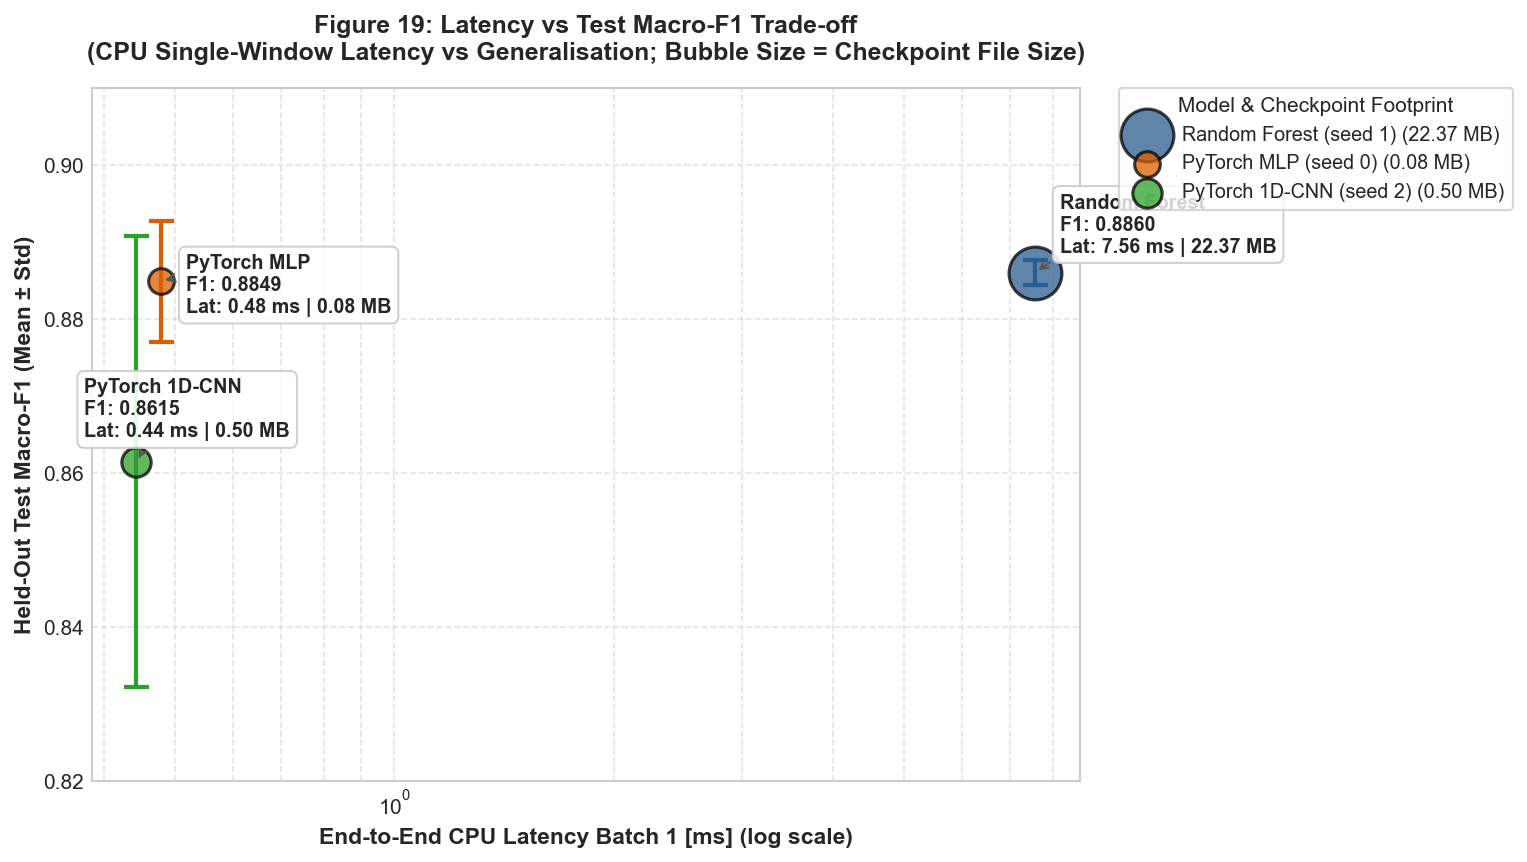

In [4]:
fig19_path = Path("outputs/figures/fig19_tradeoff.png")
if fig19_path.is_file():
    ipd.display(ipd.Image(filename=str(fig19_path), width=750))
else:
    print(f"Warning: Figure 19 not found at {fig19_path}")


### Recommendation (Task T5a)

**I recommend the PyTorch MLP** for an activity-tracking phone app used by new people.

- **Accuracy:** its test macro-F1 (0.885 ± 0.008) is the same as the Random Forest's (0.886 ± 0.002) within seed-to-seed variation.
- **Size and speed:** it is about 280 times smaller (0.08 MB vs 22.37 MB) and about 16 times faster per window (0.48 ms vs 7.56 ms, batch size 1, end-to-end, on the laptop CPU above). Both matter on a phone.
- **When the simpler model is better:** the Random Forest is the safer choice when consistent results matter most. It varied least between seeds, had the best worst-subject score (0.824 on subject 18), and coped better with the tilted-phone recording (49% of windows wrong, vs 96% for the MLP and 98% for the CNN).
- **When the CNN is better:** only if noisy sensor input is expected. It kept 0.606 macro-F1 at noise level σ = 0.5, while the MLP fell to 0.217 and the Random Forest to 0.233. On clean data it is the least accurate (0.861) and the least stable (± 0.029).

**Not deployment-ready:** all models score 0.04–0.09 lower on test than on validation, the test set has only 4 people, and the tilted-phone recording defeats the recommended MLP (section 4.2).


## 4. Practical Real-Time Inference CLI Pipeline (Task T5b)

The inference module `src/predict.py` is a working command-line prototype (not deployment-ready; see section 6):
- **CLI Syntax**:
  ```bash
  python -m src.predict --model {rf,mlp,cnn} --input <file.csv> [--seed K] [--json]
  ```
- **Input Contract**:
  - Exactly 12 MotionSense sensor columns in any order (extra columns and unnamed index columns ignored).
  - Assumed 50 Hz sampling rate. Minimum length: $\ge 128$ samples (2.56 s).
  - Sliding windowing: window length 128 samples, stride 64 samples (50% overlap).
- **Out-of-Scope Domain Shift Guardrails**:
  1. **Sensor Value Bounds**: Flags any channel exceeding the training min/max bounds by $>10\%$ (derived strictly from `outputs/preprocessing/channel_ranges.json`).
  2. **Gravity Norm Invariance**: Checks $|\|\mathbf{g}\| - 1.0| > 0.05\text{ g}$ to detect uncalibrated or non-MotionSense sensors.
  3. **Low Confidence Alert**: Flags predictions where $\max P(\text{class}) < 0.50$.
- **Validation & Error Handling**:
  - Rejects missing files, empty files, malformed columns, NaNs/Infs, or insufficient lengths with clean error messages and non-zero exit codes (no Python tracebacks).


In [5]:
# 4.1 Valid Sample Demonstration (Test Subject 8, wlk_7, rows 500-999)
valid_sample = "samples/valid_walking_subject8.csv"

print("--- Running recommended PyTorch MLP (seed 0) on Valid Sample ---")
res_mlp = subprocess.run(
    [sys.executable, "-m", "src.predict", "--model", "mlp", "--input", valid_sample],
    capture_output=True, text=True
)
print(res_mlp.stdout)


--- Running recommended PyTorch MLP (seed 0) on Valid Sample ---


Predicted activity: WALKING (mean confidence 0.96)
Windows: 6

Per-Class Mean Probability Table:
Code   Activity       Mean Probability   Visual Bar
-------------------------------------------------------
dws    downstairs     0.0251             |=
ups    upstairs       0.0168             |
wlk    walking        0.9567             |========================
jog    jogging        0.0004             |
std    standing       0.0011             |
sit    sitting        0.0000             |
-------------------------------------------------------

Per-Window Predictions (total 6 windows):
Win #   Start..End     Predicted Activity Confidence
-------------------------------------------------------
1       0..128         WALKING (wlk)      0.9952
2       64..192        WALKING (wlk)      0.9912
3       128..256       WALKING (wlk)      0.7991
4       192..320       WALKING (wlk)      0.9646
5       256..384       WALKING (wlk)      0.9974
6       320..448       WALKING (wlk)      0.9927
----------

In [6]:
# 4.2 Known Physical Failure Demonstration (Test Subject 1, wlk_7, rows 500-999)
# Demonstrates sensor orientation sensitivity identified in Phase 4 error analysis
failure_sample = "samples/failure_walking_subject1.csv"

print("--- Running PyTorch MLP (seed 0) on Tilted-Phone Walking Sample (true activity: walking) ---")
res_fail = subprocess.run(
    [sys.executable, "-m", "src.predict", "--model", "mlp", "--input", failure_sample],
    capture_output=True, text=True
)
print(res_fail.stdout)


--- Running PyTorch MLP (seed 0) on Tilted-Phone Walking Sample (true activity: walking) ---


Predicted activity: UPSTAIRS (mean confidence 0.98)
Windows: 6

Per-Class Mean Probability Table:
Code   Activity       Mean Probability   Visual Bar
-------------------------------------------------------
dws    downstairs     0.0012             |
ups    upstairs       0.9829             |=========================
wlk    walking        0.0088             |
jog    jogging        0.0067             |
std    standing       0.0003             |
sit    sitting        0.0001             |
-------------------------------------------------------

Per-Window Predictions (total 6 windows):
Win #   Start..End     Predicted Activity Confidence
-------------------------------------------------------
1       0..128         UPSTAIRS (ups)     0.9693
2       64..192        UPSTAIRS (ups)     0.9662
3       128..256       UPSTAIRS (ups)     0.9935
4       192..320       UPSTAIRS (ups)     0.9902
5       256..384       UPSTAIRS (ups)     0.9837
6       320..448       UPSTAIRS (ups)     0.9947
---------

In [7]:
# 4.3 Out-of-Scope Warning Demonstration (Magnified Acceleration x20)
oos_sample = "samples/out_of_scope_scaled.csv"

print("--- Running PyTorch MLP (seed 0) on Out-of-Scope Scaled Sample ---")
res_oos = subprocess.run(
    [sys.executable, "-m", "src.predict", "--model", "mlp", "--input", oos_sample],
    capture_output=True, text=True
)
print(res_oos.stdout)


--- Running PyTorch MLP (seed 0) on Out-of-Scope Scaled Sample ---



!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
OUT-OF-SCOPE WARNING(S) DETECTED:
  [!] Channel 'userAcceleration.x' has values outside training range by >10% (observed range [-12.5763, 12.9624], training bound [-7.7183, 8.4698]). Input exhibits large domain shift; prediction may be unreliable.
  [!] Channel 'userAcceleration.y' has values outside training range by >10% (observed range [-15.9209, 22.4323], training bound [-6.9732, 8.6224]). Input exhibits large domain shift; prediction may be unreliable.
  [!] Channel 'userAcceleration.z' has values outside training range by >10% (observed range [-11.9723, 10.3427], training bound [-9.3304, 9.7122]). Input exhibits large domain shift; prediction may be unreliable.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

Predicted activity: JOGGING (mean confidence 1.00)
Windows: 6

Per-Class Mean Probability Table:
Code   Activity       Mean Probability   Visual Bar
---------------------------

In [8]:
# 4.4 Schema and Integrity Validation Demonstrations (Expected Non-Zero Exit Codes)
invalid_cases = [
    ("Short Input (<128 rows)", "samples/invalid_short.csv"),
    ("Missing Required Column", "samples/invalid_columns.csv"),
    ("Corrupted NaN Entries", "samples/invalid_nan.csv"),
    ("Non-Existent File", "samples/non_existent.csv"),
]

for label, filepath in invalid_cases:
    res = subprocess.run(
        [sys.executable, "-m", "src.predict", "--model", "mlp", "--input", filepath],
        capture_output=True, text=True
    )
    print(f"Case: {label}")
    print(f"  Command: python -m src.predict --model mlp --input {filepath}")
    print(f"  Exit Code: {res.returncode} (Expected Non-Zero)")
    print(f"  Stderr Output: {res.stderr.strip()}")
    print("-" * 75)


Case: Short Input (<128 rows)
  Command: python -m src.predict --model mlp --input samples/invalid_short.csv
  Exit Code: 1 (Expected Non-Zero)
  Stderr Output: Error: Input CSV has only 60 rows. Need at least 2.56 s of data at 50 Hz (128 samples).
---------------------------------------------------------------------------


Case: Missing Required Column
  Command: python -m src.predict --model mlp --input samples/invalid_columns.csv
  Exit Code: 1 (Expected Non-Zero)
  Stderr Output: Error: Missing required sensor column(s): ['userAcceleration.z']. Input must contain all 12 MotionSense sensor columns: ['attitude.roll', 'attitude.pitch', 'attitude.yaw', 'gravity.x', 'gravity.y', 'gravity.z', 'rotationRate.x', 'rotationRate.y', 'rotationRate.z', 'userAcceleration.x', 'userAcceleration.y', 'userAcceleration.z'].
---------------------------------------------------------------------------


Case: Corrupted NaN Entries
  Command: python -m src.predict --model mlp --input samples/invalid_nan.csv
  Exit Code: 1 (Expected Non-Zero)
  Stderr Output: Error: Non-numeric, NaN, or Inf values found at row index/indices: [12, 25, 50].
---------------------------------------------------------------------------


Case: Non-Existent File
  Command: python -m src.predict --model mlp --input samples/non_existent.csv
  Exit Code: 1 (Expected Non-Zero)
  Stderr Output: Error: Input file 'samples\non_existent.csv' does not exist.
---------------------------------------------------------------------------


In [9]:
# 4.5 Structured JSON Mode Demonstration (--json flag)
res_json = subprocess.run(
    [sys.executable, "-m", "src.predict", "--model", "mlp", "--input", valid_sample, "--json"],
    capture_output=True, text=True
)
parsed_json = json.loads(res_json.stdout)

print("Parsed JSON Summary:")
print(f"  Model:              {parsed_json['model']} (seed {parsed_json['seed']})")
print(f"  Predicted Activity: {parsed_json['predicted_activity']} ({parsed_json['predicted_code']})")
print(f"  Mean Confidence:    {parsed_json['mean_confidence']:.4f}")
print(f"  Windows Analyzed:   {parsed_json['n_windows']}")
print("  Class Probabilities:")
for code, prob in parsed_json['mean_class_probabilities'].items():
    print(f"    {code}: {prob:.4f}")


Parsed JSON Summary:
  Model:              mlp (seed 0)
  Predicted Activity: WALKING (wlk)
  Mean Confidence:    0.9567
  Windows Analyzed:   6
  Class Probabilities:
    dws: 0.0251
    ups: 0.0168
    wlk: 0.9567
    jog: 0.0004
    std: 0.0011
    sit: 0.0000


## 5. Tracing One Result: Config → Checkpoint → Metrics → Figure (Task T6b)

This follows the recommended model (PyTorch MLP, seed 0) from its frozen configuration to its reported test score.
Every value below is read from saved files; nothing is retrained or re-evaluated.


In [10]:
import yaml

cfg_path = Path("configs/mlp_final.yaml")
snap_path = Path("outputs/checkpoints/pytorch_mlp_seed0_config.yaml")
ckpt_path = Path("outputs/checkpoints/pytorch_mlp_seed0.pt")
info_path = Path("outputs/checkpoints/run_info_pytorch_mlp_seed0.json")

# Step 1: frozen configuration
print("STEP 1 - Frozen configuration:", cfg_path)
print(cfg_path.read_text())

# Step 2: the config copy saved next to the checkpoint must match the frozen config
cfg = yaml.safe_load(cfg_path.read_text())
snap = yaml.safe_load(snap_path.read_text())
print("STEP 2 - Checkpoint:", ckpt_path, f"({ckpt_path.stat().st_size / 1024:.1f} KB)")
for section in ["model", "training"]:
    same = cfg.get(section) == snap.get(section)
    print(f"  '{section}' settings in saved snapshot match frozen config: {same}")

# Step 3: environment recorded at training time
info = json.loads(info_path.read_text())
print()
print("STEP 3 - Run environment:", info_path)
for key in ["timestamp", "python_version", "torch_version", "cpu_name", "seed"]:
    if key in info:
        print(f"  {key}: {info[key]}")

# Step 4: the row in the results table produced by src/evaluate.py (test set used once)
results = pd.read_csv("outputs/metrics/results_table.csv")
row = results[(results["model"] == "pytorch_mlp") & (results["seed"] == 0)]
print()
print("STEP 4 - Row in outputs/metrics/results_table.csv:")
print(row.to_string(index=False))


STEP 1 - Frozen configuration: configs\mlp_final.yaml
model:
  dropout: 0.2
  hidden_sizes:
  - 128
  - 64
  input_dim: 84
  name: pytorch_mlp
  num_classes: 6
seeds:
- 0
- 1
- 2
training:
  batch_size: 64
  learning_rate: 0.001
  loss: cross_entropy
  max_epochs: 60
  patience: 8
  use_class_weights: false
  weight_decay: 0.0001

STEP 2 - Checkpoint: outputs\checkpoints\pytorch_mlp_seed0.pt (85.5 KB)
  'model' settings in saved snapshot match frozen config: True
  'training' settings in saved snapshot match frozen config: True

STEP 3 - Run environment: outputs\checkpoints\run_info_pytorch_mlp_seed0.json
  timestamp: 2026-11-10T05:45:44.086093+00:00
  python_version: 3.11.9
  torch_version: 2.15.0+cpu
  cpu_name: 11th Gen Intel(R) Core(TM) i5-11400H @ 2.70GHz
  seed: 0

STEP 4 - Row in outputs/metrics/results_table.csv:
      model            config_file  seed  best_epoch  val_macro_f1  test_macro_f1  test_accuracy  n_params                          checkpoint_path
pytorch_mlp configs

STEP 5 - Test confusion matrix: outputs\figures\fig11_cm_mlp.png


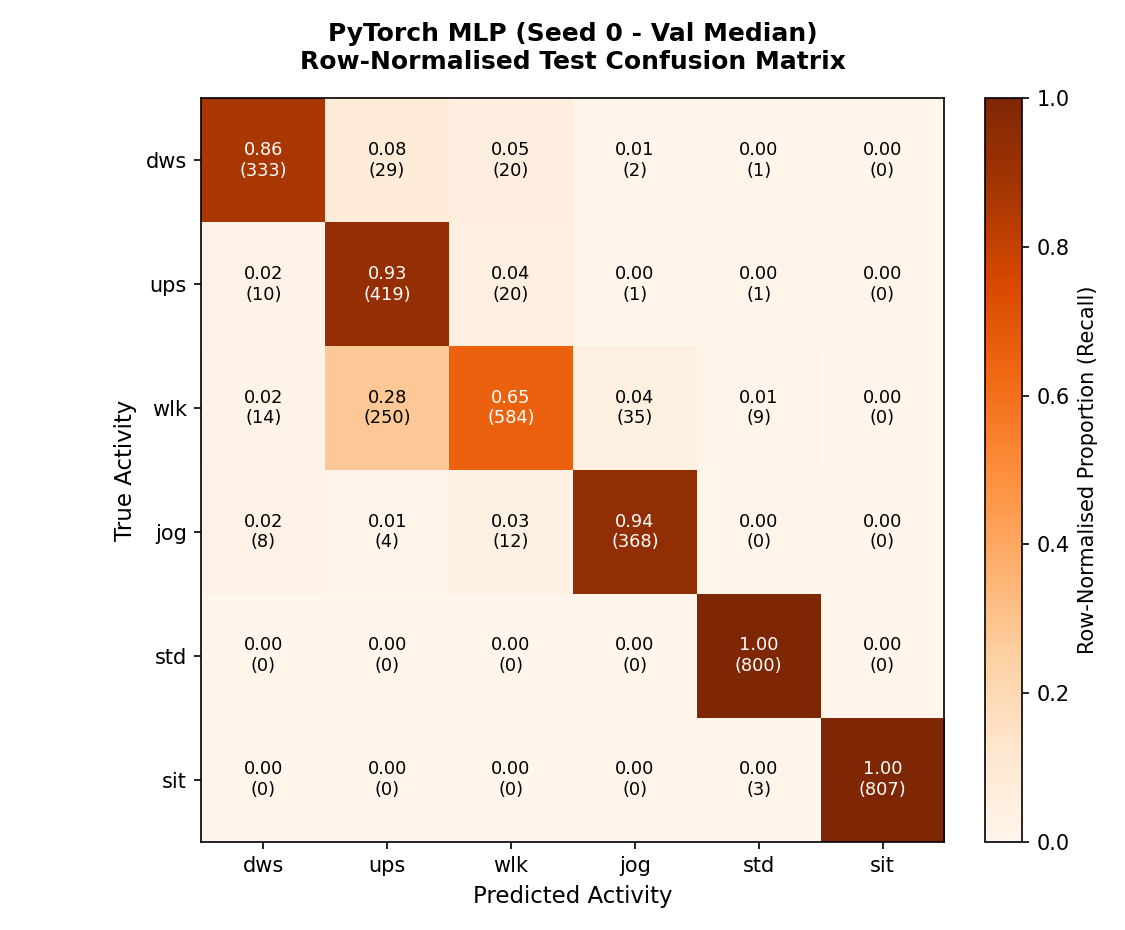

In [11]:
# Step 5: confusion matrix for this checkpoint on the test set
fig11_path = Path("outputs/figures/fig11_cm_mlp.png")
print("STEP 5 - Test confusion matrix:", fig11_path)
ipd.display(ipd.Image(filename=str(fig11_path), width=600))


## 6. Limitations & Future Directions (Task T5c)

These results are useful for comparing the three models with each other. They do **not** show that any of them is ready to be used in a real app. This section explains why.

### Dataset bias

**What the problem is:** the data comes from a small and very similar group.
- Only **24 people**, all adults aged **18 to 46**. There are no children or people over 46, and the dataset says nothing about people with mobility problems (for example walking with a stick).
- Everyone used the **same phone model** (an iPhone) and carried it in the **same way**. A different phone, or a phone in a bag, hand or jacket, would give different signals.
- The activities were recorded as planned trials, not during normal daily life, so they may be "cleaner" than real movement.
- The classes are uneven: in training there are 3,488 sitting windows but only 1,226 downstairs windows.

**Why it matters:** a model can only learn what it has seen. People who move differently from these 24 are likely to get worse predictions, and we have no data to measure how much worse.

### Generalisation

**What the problem is:** the models do worse on new people, and some recordings break them completely.
- Every model scored **0.04 to 0.09 lower** on the 4 test people than on the 4 validation people. New people are harder than the numbers on validation suggest.
- The test score comes from only **4 people**. One unusual person can move the result a lot, so the "true" score for the general public could be noticeably higher or lower.
- **Tilted phone (subject 1, walking trial 7):** the phone sat at a different angle in the pocket. The MLP got 96% of windows wrong and the CNN 98%; the Random Forest did better but still got 49% wrong. Instead of walking, the CNN mostly predicted "upstairs" and the MLP "upstairs" or "jogging", often with high confidence.
- **Another walking recording (subject 21, trial 7)** also fails for all three models (86–93% of windows wrong). We have not yet found the cause, which shows we do not fully understand where the models break.
- The models are often **confidently wrong** (for example 0.98 confidence for the wrong activity), so the confidence score cannot be trusted to warn the user.

**Why it matters:** an app built on these models would work well for some people and badly for others, and it could not tell which is which.

### Privacy & misuse

**What the problem is:** motion data is more personal than it looks.
- The way someone walks is close to a **fingerprint**: it can be used to identify a person.
- Activity patterns can reveal **health** (for example, slowing down over time, or difficulty with stairs) and **daily routine** (when someone is home, asleep or out).
- The same model could be **misused** to track people without their knowledge, for example by an employer or an insurer.

**What should be done:** run predictions **on the phone itself** so raw sensor data never leaves the device, ask for clear **consent**, store only the predicted activity (not the raw signals), and let users delete their data.

### Next experiment

**Idea:** many errors seem to come from the phone being held at a different angle. So, during training, **randomly rotate the sensor signals** to imitate the phone being tilted in different ways. This teaches the model that the same movement can look different depending on how the phone sits.

**How to test it fairly:**
- Keep everything else the same: the same subject split, the same 3 seeds, the same settings, chosen on validation only.
- Compare against the current MLP using macro-F1 on the test set, and look at the tilted recording (subject 1, walking trial 7) separately.
- **The idea has failed if** test macro-F1 does not improve beyond the seed-to-seed variation, or if the tilted recording is still mostly wrong.
